# Project 2.2 - MMIMDB Multi Modal Analysis

### Sebastian Warr - A1852720

This project aims to predict movie genres from 23 possible categories by combining movie posters and plot
summaries from IMDb. Automated genre classification could improve film metadata and support
recommendation systems, helping viewers discover relevant movies.

This notebook file contains all of the data analysis conducted for the project as decribed in the project report and recorded in the presentation. I have provided headings and some markdown text for readability and to follow with the analysis. For the main discussion on this project please read the main report as provided.

#### Task 1: Data Setup, Cleaning and Preproccessing

##### Setup and Loading

The dataset is stored under the zip file downloaded from Kaggle. We can extract the two files that are needed for the analysis out, the .hdf5 that includes posters, plots and labels, and the metadata file that is a lookup table from word numbers back to words. 

In order to avoid extracting these files multiple times, a skip has been put it to save time and disk space. A cache has been created that avoids repeating slow work. 

In [1]:
import zipfile, shutil, pathlib, pickle
import numpy as np, pandas as pd, h5py
import matplotlib.pyplot as plt

ZIP = pathlib.Path("mmimdb.zip")
DATA = pathlib.Path("mmimdb")
CACHE = pathlib.Path("cache")
DATA.mkdir(exist_ok=True); CACHE.mkdir(exist_ok=True)

GENRES = ["Drama","Comedy","Romance","Thriller","Crime","Action","Adventure","Horror","Documentary",
          "Mystery","Sci-Fi","Fantasy","Family","Biography","War","History","Music","Animation",
          "Musical","Western","Sport","Short","Film-Noir"]

def cached(name, fn, force=False):
    """Run fn() once, save the result to disk, and reload it on later runs."""
    p = CACHE / f"{name}.pkl"
    if p.exists() and not force:
        return pickle.load(open(p, "rb"))
    out = fn()
    pickle.dump(out, open(p, "wb"))
    return out

def ensure_extracted():
    """Pull the two files we need out of the zip, unless they are already there."""
    needed = ["multimodal_imdb.hdf5", "metadata.npy"]
    if all((DATA / n).exists() for n in needed):
        print("Dataset already unzipped")
        return
    free_gb = shutil.disk_usage(".").free / 1e9
    print(f"Unzipping (free disk space: {free_gb:.1f} GB) ...")
    with zipfile.ZipFile(ZIP) as z:
        for n in needed:
            match = [m for m in z.namelist() if m.endswith(n)]
            assert match, f"{n} not found inside {ZIP}"
            with z.open(match[0]) as src, open(DATA / n, "wb") as dst:
                shutil.copyfileobj(src, dst)
    print("Done.")

ensure_extracted()

with h5py.File(DATA / "multimodal_imdb.hdf5", "r") as f:
    for name, obj in f.items():
        print(f"{name:15s} {obj.shape}  {obj.dtype}")

Dataset already unzipped
features        (25959, 300)  float32
genres          (25959, 23)  int32
images          (25959, 3, 256, 160)  int32
imdb_ids        (25959,)  |S7
sequences       (25959,)  object
three_grams     (25959, 9946)  float32
vgg_features    (25959, 4096)  float32
word_grams      (25959, 13253)  float32


##### Data Quality

In the file already contains pre defined features, of which are not used in this analysis. The data is loaded here that includes the labels, the movie ids and plots. The posters are not yet loaded, and read in small batches when they are needed.

In [2]:
def load_core():
    meta = np.load(DATA / "metadata.npy", allow_pickle=True).item()
    i2w = meta["ix_to_word"]                                   # word number -> word
    word = (lambda i: i2w.get(i, i2w.get(str(i), "<?>"))) if isinstance(i2w, dict) \
        else (lambda i: i2w[i] if 0 <= i < len(i2w) else "<?>")
    with h5py.File(DATA / "multimodal_imdb.hdf5", "r") as f:
        return dict(
            Y=f["genres"][:].astype("float32"),                # labels: 0/1 per genre
            ids=f["imdb_ids"][:].astype(str),                  # movie ids
            plots=[" ".join(str(word(int(i))) for i in s) for s in f["sequences"][:]])

core = cached("core_raw", load_core)
Y, ids, plots = core["Y"], core["ids"], core["plots"]

with h5py.File(DATA / "multimodal_imdb.hdf5", "r") as f:
    print("Posters:", f["images"].shape, f["images"].dtype, "(movies, colour channels, height, width)")
print("Labels:", Y.shape, "| plots:", len(plots))
print("Movie", ids[0], "->", [GENRES[j] for j in np.where(Y[0])[0]])
print("Plot:", plots[0][:300])

Posters: (25959, 3, 256, 160) int32 (movies, colour channels, height, width)
Labels: (25959, 23) | plots: 25959
Movie 0028219 -> ['Drama', 'Thriller', 'Mystery', 'Film-Noir']
Plot: sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethought to provide himself with a N - dollar commission from an old lady on the train , is welcomed with 


Data analysis and check for different issues that may be found within the dataset. This includes:

Nearly Blank Posters

Empty Plots

Plots under 10 under 10 words

Plot Lengths

Duplicate Movie IDS

Movies with no genre

Mean genres per movie

In [3]:
def poster_stats(chunk=256):
    """Average and spread of the pixel values of every poster, read in small batches."""
    out = []
    with h5py.File(DATA / "multimodal_imdb.hdf5", "r") as f:
        for a in range(0, f["images"].shape[0], chunk):
            x = f["images"][a:a + chunk].astype("float32").reshape(-1, 3 * 256 * 160)
            out.append(np.stack([x.mean(1), x.std(1)], 1))
    return np.concatenate(out)

pstats = cached("poster_stats", poster_stats)            # a few minutes the first time, instant after
n_words = np.array([len(p.split()) for p in plots])

quality = pd.Series({
    "movies": len(Y),
    "nearly blank posters (pixel std < 5)": int((pstats[:, 1] < 5).sum()),
    "empty plots (0 words)": int((n_words == 0).sum()),
    "plots under 10 words": int((n_words < 10).sum()),
    "plot length: median words": float(np.median(n_words)),
    "duplicate movie ids": int(len(ids) - len(set(ids))),
    "movies with no genre": int((Y.sum(1) == 0).sum()),
    "mean genres per movie": round(float(Y.sum(1).mean()), 2),
}, name="value")
quality.to_frame()

,value
movies,25959.00
nearly blank posters (pixel std < 5),0.00
empty plots (0 words),0.00
plots under 10 words,144.00
plot length: median words,107.00
duplicate movie ids,0.00
movies with no genre,0.00
mean genres per movie,2.48


##### Exploration

Posters within the dataset are stored in reverse order (BGR instead of RGB), this needs to be fixed by reversing the chanels, moving the colour axis to the end, and rescaling. This helps to view the posters for and eye test.

The genres of movies are also found in this analysis, seeing the class inbalance between the dataset.

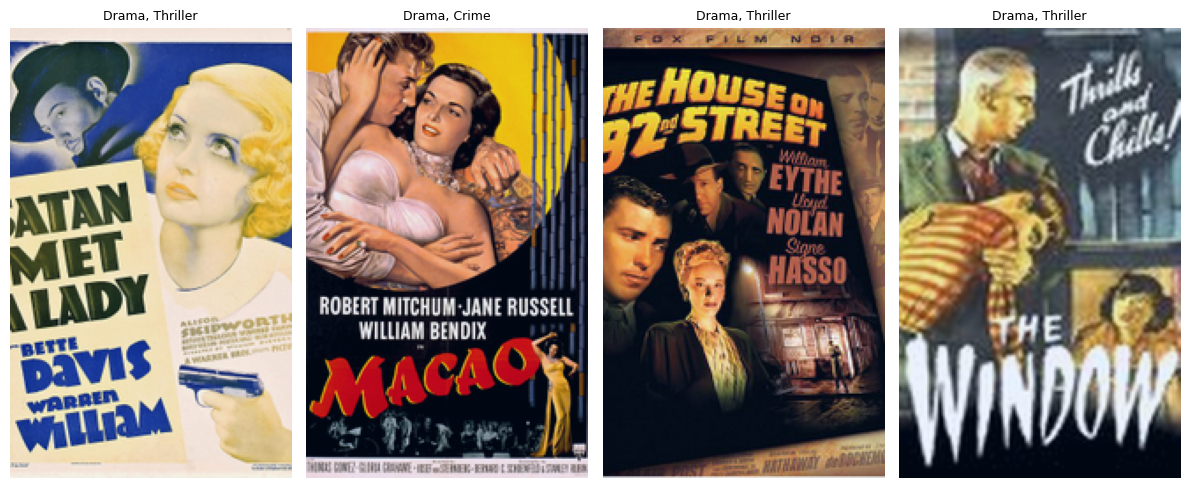

Movie 0028219: sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethoug ...

Movie 0044863: a sultry night club singer , a man who has also traveled to many exotic ports and a salesman meet aboard ship on the N - mile trip from hong kong to macao . the singer is quickly hired by an american  ...

Movie 0037795: prior to the united states entering wwii , the fbi is monitoring known and suspected nazi agents in the country . purely by happenstance , they discover a nazi cell in the us trying to smuggle informa ...

Movie 0042046: the woodrys live in a new york city tenement . nine year old tommy woodry has a penchant for telling what he considers are harmless stories of fancy . most of the people to who he tells the stories kn ...



In [4]:
with h5py.File(DATA / "multimodal_imdb.hdf5", "r") as f:
    x = f["images"][0]

    fig, axes = plt.subplots(1, 4, figsize=(12, 5))
    for ax, i in zip(axes, range(4)):
        img = f["images"][i][::-1].astype("float32")
        img = np.transpose(img, (1, 2, 0))
        img = (img - img.min()) / (img.max() - img.min())
        ax.imshow(img); ax.axis("off")
        ax.set_title(", ".join(GENRES[j] for j in np.where(Y[i])[0][:2]), fontsize=9)
plt.tight_layout(); plt.show()

for i in range(4):
    print(f"Movie {ids[i]}:", plots[i][:200], "...\n")

In [5]:
genre_table = pd.DataFrame({
    "Genre": GENRES,
    "Movies": Y.sum(axis=0).astype(int),
})

genre_table["% of movies"] = genre_table["Movies"] / len(Y) * 100
genre_table = genre_table.sort_values("Movies", ascending=False).reset_index(drop=True)

genre_table.index = genre_table.index + 1
genre_table.index.name = "Rank"

genre_table.style.format({"Movies": "{:,}", "% of movies": "{:.1f}%"})

,Genre,Movies,% of movies
Rank,,,
1,Drama,"13,967",53.8%
2,Comedy,"8,592",33.1%
3,Romance,"5,364",20.7%
4,Thriller,"5,192",20.0%
5,Crime,"3,838",14.8%
6,Action,"3,550",13.7%
7,Adventure,"2,710",10.4%
8,Horror,"2,703",10.4%
9,Documentary,"2,082",8.0%


#### Task 2: Feature Extraction

This task aims to convert movie posters and plot summaries into numerical feature representations that can be used for genre classification. Two methods have been used for both modalities in order to investigate effectiveness and to create base models to be compared with fusion in later experiments. 

The required libraries and computing device are initialised before feature extraction. The dataset is split into training, validation and test sets. 

Caching has also been added here. Prior to this, sometimes code that has been run that were computationally expensive would re run upon restarting the notebook.  

In [8]:
import json, time
import numpy as np, pandas as pd, h5py, torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU found")

H5 = DATA / "multimodal_imdb.hdf5"
N = len(Y)

if "idx" not in globals():
    tr, rest = train_test_split(np.arange(N), test_size=0.4, random_state=42)
    dv, te = train_test_split(rest, test_size=0.75, random_state=42)
    idx = dict(train=tr, dev=dv, test=te)
print({k: len(v) for k, v in idx.items()})

def cached_array(name, make):
    """Compute an array once, save it as cache/<name>.npy, and load it on later runs."""
    path = CACHE / f"{name}.npy"
    if path.exists():
        print(f"{name}: loaded from cache")
        return np.load(path)
    arr = make()
    np.save(path, arr)
    return arr

TIMES_FILE = CACHE / "extraction_times.json"
times = json.load(open(TIMES_FILE)) if TIMES_FILE.exists() else {}

def timed(name, make):
    """cached_array, plus the extraction time stored in extraction_times.json."""
    def run():
        t = time.time()
        out = make()
        times[name] = round(time.time() - t, 1)
        json.dump(times, open(TIMES_FILE, "w"))
        return out
    return cached_array(name, run)

Device: cpu | no GPU found
{'train': 15575, 'dev': 2596, 'test': 7788}


The posters are currently stored in BGR colour format. They are converted back to RGB, rescaled and normalised to make sure they work with the ImageNet statistics. These are inspected to make sure they have been reconstructed correctly.

In [9]:
BGR_MEAN = np.array([103.939, 116.779, 123.68], dtype="float32").reshape(1, 3, 1, 1)

def read_rows(dataset, rows):
    """Read the given rows (sorted, no repeats) from an HDF5 dataset. Consecutive rows use a fast slice."""
    rows = np.asarray(rows)
    if rows[-1] - rows[0] + 1 == len(rows):
        return dataset[rows[0]:rows[-1] + 1]
    return dataset[list(rows)]

def to_rgb(raw, mean_subtracted):
    """Stored posters -> RGB colours scaled to 0-1, shape (n, 3, 256, 160)."""
    x = raw.astype("float32")
    if mean_subtracted:
        x = x + BGR_MEAN
    x = x[:, ::-1]
    return np.ascontiguousarray(np.clip(x, 0, 255) / 255.0, dtype="float32")

def posters_rgb(dataset, rows, mean_subtracted):
    return to_rgb(read_rows(dataset, rows), mean_subtracted)

Raw pixel range: -123 to 151
Mean subtracted: True


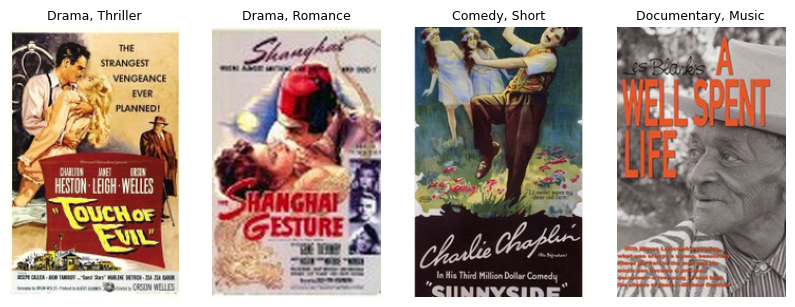

In [10]:
SAMPLE = np.sort(np.random.default_rng(0).choice(N, 256, replace=False))

with h5py.File(H5, "r") as f:
    raw = read_rows(f["images"], SAMPLE)
print("Raw pixel range:", raw.min(), "to", raw.max())

MEAN_SUBTRACTED = bool(raw.min() < 0)
print("Mean subtracted:", MEAN_SUBTRACTED)

sample_posters = to_rgb(raw, MEAN_SUBTRACTED)
del raw

fig, axes = plt.subplots(1, 4, figsize=(10, 4))
for ax, pos in zip(axes, range(4)):
    ax.imshow(sample_posters[pos].transpose(1, 2, 0)); ax.axis("off")
    ax.set_title(", ".join(GENRES[j] for j in np.where(Y[SAMPLE[pos]])[0][:2]), fontsize=9)
plt.show()

The two ImageNet models (VGG-16 and ResNet-50) are loaded with their final classifacation layers removed. The weights are frozen so is allows to the act as feature extractors and not being retrained on the movie dataset. 

Features are extracted in batches. A sample is initially done to check the output dimensions and approximate time

In [11]:
import ssl, certifi
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())

In [12]:
from torchvision import models

IMG_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMG_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def build_image_encoder(name):
    """Pretrained ImageNet network with the final classification layer removed (frozen, evaluation mode)."""
    if name == "vgg16":
        m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        enc = nn.Sequential(m.features, m.avgpool, nn.Flatten(), m.classifier[:5])
    elif name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        enc = nn.Sequential(*list(m.children())[:-1], nn.Flatten())
    else:
        raise ValueError(name)
    return enc.to(device).eval()

def extract_images(enc, rows, batch=64):
    """Poster features for the given rows, one batch at a time."""
    out = []
    with h5py.File(H5, "r") as f, torch.no_grad():
        for a in range(0, len(rows), batch):
            x = posters_rgb(f["images"], rows[a:a + batch], MEAN_SUBTRACTED)
            x = (torch.from_numpy(x) - IMG_MEAN) / IMG_STD
            out.append(enc(x.to(device)).cpu().numpy())
    return np.concatenate(out)

encoders = {name: build_image_encoder(name) for name in ["vgg16", "resnet50"]}

In [13]:
def check_features(name, F, seconds=None):
    msg = (f"{name}: shape {F.shape} | NaN: {bool(np.isnan(F).any())} | "
           f"all-zero rows: {int((np.abs(F).sum(1) == 0).sum())} | mean {F.mean():.3f}, std {F.std():.3f}")
    if seconds is not None:
        msg += f" | about {seconds / len(F) * N / 60:.1f} min for all {N:,} movies"
    print(msg)

test_img = {}
for name, enc in encoders.items():
    t = time.time()
    test_img[name] = extract_images(enc, SAMPLE)
    check_features(name, test_img[name], time.time() - t)

vgg16: shape (256, 4096) | NaN: False | all-zero rows: 0 | mean 0.225, std 0.570 | about 35.4 min for all 25,959 movies
resnet50: shape (256, 2048) | NaN: False | all-zero rows: 0 | mean 0.480, std 0.459 | about 17.6 min for all 25,959 movies


BERT is used to generate contextualised representations of the movie plot summaries. Plots are tokenised with a maximum sequence length of 256 tokens, and the final hidden states are mean-pooled while ignoring padding tokens.

Word2Vec provides a simpler alternative to BERT. The model is trained on the training plot summaries only, without using genre labels. Each word is represented by a 100-dimensional vector, with the vectors averaged to produce one feature representation per movie.

In [14]:
from transformers import BertTokenizerFast, BertModel

tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")
bert = BertModel.from_pretrained("bert-base-uncased").to(device).eval()
MAX_LEN = 256

check_rows = np.random.default_rng(1).choice(N, 3000, replace=False)
lengths = np.array([len(x) for x in tokenizer([plots[i] for i in check_rows], truncation=False)["input_ids"]])
print(f"Median length: {np.median(lengths):.0f} tokens | longer than {MAX_LEN}: {100 * (lengths > MAX_LEN).mean():.1f}% of plots")

def extract_bert(texts, batch=32):
    """Mean-pooled BERT vector per plot (same recipe as Week 8), ignoring padding tokens."""
    out = []
    with torch.no_grad():
        for a in range(0, len(texts), batch):
            enc = tokenizer(texts[a:a + batch], return_tensors="pt", padding=True,
                            truncation=True, max_length=MAX_LEN).to(device)
            hidden = bert(**enc).last_hidden_state
            mask = enc["attention_mask"].unsqueeze(-1)
            out.append(((hidden * mask).sum(1) / mask.sum(1)).cpu().numpy())
    return np.concatenate(out)

t = time.time()
test_bert = extract_bert([plots[i] for i in SAMPLE])
check_features("bert", test_bert, time.time() - t)

C:\Users\sebwa\anaconda3\envs\cv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Token indices sequence length is longer than the specified maximum sequence length for this model (593 > 512). Running this sequence through the model will result in indexing errors


Median length: 117 tokens | longer than 256: 10.8% of plots
bert: shape (256, 768) | NaN: False | all-zero rows: 0 | mean -0.013, std 0.308 | about 70.8 min for all 25,959 movies


In [15]:
from gensim.models import Word2Vec

def extract_word2vec(dim=100):
    """Train Word2Vec on the training plots only (no labels used), then average the word vectors of each plot."""
    corpus = [plots[i].split() for i in idx["train"]]
    w2v = Word2Vec(sentences=corpus, vector_size=dim, window=5, min_count=2, workers=1, seed=0, epochs=20)
    def average(text):
        vecs = [w2v.wv[w] for w in text.split() if w in w2v.wv]
        return np.mean(vecs, axis=0) if vecs else np.zeros(dim)
    return np.stack([average(p) for p in plots]).astype("float32")

txt_w2v = timed("txt_w2v", extract_word2vec)
check_features("word2vec", txt_w2v)

txt_w2v: loaded from cache
word2vec: shape (25959, 100) | NaN: False | all-zero rows: 0 | mean -0.040, std 0.338


In [16]:
ALL = np.arange(N)

img_vgg16    = timed("img_vgg16",    lambda: extract_images(encoders["vgg16"], ALL))
img_resnet50 = timed("img_resnet50", lambda: extract_images(encoders["resnet50"], ALL))
txt_bert     = timed("txt_bert",     lambda: extract_bert(plots))

for name, F in [("VGG-16", img_vgg16), ("ResNet-50", img_resnet50), ("BERT", txt_bert)]:
    check_features(name, F)

img_vgg16: loaded from cache
img_resnet50: loaded from cache
txt_bert: loaded from cache
VGG-16: shape (25959, 4096) | NaN: False | all-zero rows: 0 | mean 0.224, std 0.568
ResNet-50: shape (25959, 2048) | NaN: False | all-zero rows: 0 | mean 0.478, std 0.461
BERT: shape (25959, 768) | NaN: False | all-zero rows: 0 | mean -0.013, std 0.308


In [17]:
for name, full, sample in [("VGG-16", img_vgg16, test_img["vgg16"]),
                           ("ResNet-50", img_resnet50, test_img["resnet50"]),
                           ("BERT", txt_bert, test_bert)]:
    print(f"{name}: largest difference on the same movies = {np.abs(full[SAMPLE] - sample).max():.1e}")

VGG-16: largest difference on the same movies = 0.0e+00
ResNet-50: largest difference on the same movies = 0.0e+00
BERT: largest difference on the same movies = 7.2e-07


In [18]:
summary = pd.DataFrame([
    {"Modality": "Poster", "Encoder": "VGG-16 (fc7)",         "Key": "img_vgg16",    "F": img_vgg16},
    {"Modality": "Poster", "Encoder": "ResNet-50",            "Key": "img_resnet50", "F": img_resnet50},
    {"Modality": "Plot",   "Encoder": "BERT (mean-pooled)",   "Key": "txt_bert",     "F": txt_bert},
    {"Modality": "Plot",   "Encoder": "Word2Vec (averaged)",  "Key": "txt_w2v",      "F": txt_w2v},
])
summary["Dimensions"] = summary["F"].apply(lambda F: F.shape[1])
summary["Size (MB)"] = summary["F"].apply(lambda F: round(F.nbytes / 1e6))
summary["Extraction time (min)"] = summary["Key"].apply(lambda k: round(times.get(k, float("nan")) / 60, 1))
summary.drop(columns=["Key", "F"])

,Modality,Encoder,Dimensions,Size (MB),Extraction time (min)
0,Poster,VGG-16 (fc7),4096,425,37.8
1,Poster,ResNet-50,2048,213,19.7
2,Plot,BERT (mean-pooled),768,80,68.1
3,Plot,Word2Vec (averaged),100,10,0.9


#### Task 3: Unimodal Baselines

The feature sets saved in Task 3 are loaded and standardised (mean 0, standard deviation 1 per feature) using the training movies only. A feature that is constant in the training data keeps its original scale, to avoid dividing by zero. After scaling, each set should show a training mean near 0 and a training standard deviation near 1.

In [19]:
FILES = {"VGG-16 (poster)": "img_vgg16", "ResNet-50 (poster)": "img_resnet50",
         "BERT (plot)": "txt_bert", "Word2Vec (plot)": "txt_w2v"}

def standardise(X):
    """Scale every feature with TRAIN statistics only, so nothing leaks from dev or test."""
    mu = X[idx["train"]].mean(0)
    sd = X[idx["train"]].std(0)
    sd = np.where(sd < 1e-6, 1.0, sd)
    return ((X - mu) / sd).astype("float32")

FEATURES = {name: standardise(np.load(CACHE / f"{key}.npy")) for name, key in FILES.items()}
Ytr, Ydv, Yte = (Y[idx[s]] for s in ("train", "dev", "test"))

for name, X in FEATURES.items():
    print(f"{name:20s} {X.shape} | train mean {X[idx['train']].mean():+.3f}, train std {X[idx['train']].std():.3f}")

VGG-16 (poster)      (25959, 4096) | train mean -0.000, train std 1.000
ResNet-50 (poster)   (25959, 2048) | train mean -0.000, train std 1.000
BERT (plot)          (25959, 768) | train mean -0.000, train std 1.000
Word2Vec (plot)      (25959, 100) | train mean +0.000, train std 1.000


Model performance was assessed using macro-F1, micro-F1 and macro average precision (macro-AP). Macro-F1 gives equal importance to each genre, while micro-F1 evaluates performance across all genre predictions collectively. Macro-AP measures how well the model ranks relevant genres above irrelevant ones, without relying on a fixed classification threshold.

In [20]:
from sklearn.metrics import f1_score, average_precision_score

GRID = np.arange(0.05, 0.96, 0.05)

def tune_thresholds(Yd, S):
    """Best threshold per genre, chosen on the dev set only. F1 = 2 x TP / (predicted + actual positives)."""
    best = []
    for j in range(Yd.shape[1]):
        actual = Yd[:, j] == 1
        pred = S[:, [j]] >= GRID
        tp = (pred & actual[:, None]).sum(0)
        f1 = 2 * tp / (pred.sum(0) + actual.sum() + 1e-9)
        best.append(GRID[np.argmax(f1)])
    return np.array(best)

def evaluate(Yt, S, thr):
    """Metrics for predicted probabilities S, using one threshold per genre."""
    pred = (S >= thr).astype(int)
    ap = np.array([average_precision_score(Yt[:, j], S[:, j]) for j in range(Yt.shape[1])])
    return dict(micro_f1=f1_score(Yt, pred, average="micro", zero_division=0),
                macro_f1=f1_score(Yt, pred, average="macro", zero_division=0),
                macro_f1_at_05=f1_score(Yt, (S >= 0.5).astype(int), average="macro", zero_division=0),
                macro_ap=ap.mean(), ap_per_genre=ap)

drama_only = np.zeros_like(Yte)
drama_only[:, GENRES.index("Drama")] = 1
baseline = {"micro_f1": f1_score(Yte, drama_only, average="micro", zero_division=0),
            "macro_f1": f1_score(Yte, drama_only, average="macro", zero_division=0),
            "macro_ap": Yte.mean(0).mean()}
print({k: round(v, 3) for k, v in baseline.items()})

{'micro_f1': 0.314, 'macro_f1': 0.031, 'macro_ap': np.float32(0.108)}


A separate MLP was trained for each of the four feature representations to predict the 23 movie genres. Each network contained a hidden layer of 512 neurons, using ReLU activation and dropout to help prevent overfitting. The output layer produced a probability for each genre.

Models were trained in batches of 256 for up to 60 epochs. Early stopping was used to stop training when development performance stopped improving, retaining the best-performing model. Each feature set was trained using five different random seeds to account for variation between runs.

In [21]:
import copy

HP = dict(hidden=512, dropout=0.5, lr=1e-3, wd=1e-4, bs=256, epochs=60, patience=6)
HP_TAG = f"h{HP['hidden']}_d{HP['dropout']}_lr{HP['lr']}"        # part of every saved run name

def make_mlp(d):
    return nn.Sequential(nn.Linear(d, HP["hidden"]), nn.ReLU(), nn.Dropout(HP["dropout"]), nn.Linear(HP["hidden"], 23))

def predict(model, X, bs=2048):
    model.eval()
    with torch.no_grad():
        return torch.cat([torch.sigmoid(model(X[i:i + bs])) for i in range(0, len(X), bs)]).cpu().numpy()

def macro_ap(Yt, S):
    return np.mean([average_precision_score(Yt[:, j], S[:, j]) for j in range(Yt.shape[1])])

def train_mlp(X, seed):
    """Train one network on feature matrix X. Stops when dev macro-AP has not improved for `patience` epochs."""
    torch.manual_seed(seed)
    t = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
    Xtr, Xdv, Xte = (t(X[idx[s]]) for s in ("train", "dev", "test"))
    ytr, ydv = t(Ytr), t(Ydv)
    model = make_mlp(X.shape[1]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["wd"])
    loss_fn = nn.BCEWithLogitsLoss()
    hist = dict(train_loss=[], dev_loss=[], dev_map=[], best_epoch=0)
    best, waited, best_state = -1.0, 0, None
    start = time.time()
    for epoch in range(HP["epochs"]):
        model.train()
        order = torch.randperm(len(Xtr), device=device)
        total = 0.0
        for i in range(0, len(order), HP["bs"]):
            b = order[i:i + HP["bs"]]
            loss = loss_fn(model(Xtr[b]), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            dev_loss = loss_fn(model(Xdv), ydv).item()
        dev_map = macro_ap(Ydv, predict(model, Xdv))
        hist["train_loss"].append(total / len(order)); hist["dev_loss"].append(dev_loss); hist["dev_map"].append(dev_map)
        if dev_map > best:
            best, waited, hist["best_epoch"] = dev_map, 0, epoch
            best_state = copy.deepcopy(model.state_dict())
        else:
            waited += 1
            if waited >= HP["patience"]:
                break
    model.load_state_dict(best_state)                  # go back to the best epoch
    return dict(train=predict(model, Xtr), dev=predict(model, Xdv), test=predict(model, Xte),
                hist=hist, secs=time.time() - start)

def run_model(key, X, seeds):
    """One saved run per (feature set, seed). Runs that already exist are loaded, not trained again."""
    return {s: cached(f"run_{key}_{HP_TAG}_s{s}", lambda s=s: train_mlp(X, s)) for s in seeds}

The model produces a probability for each genre, which must be converted into a genre prediction using a threshold. Rather than using the default threshold of 0.5 for every genre, different thresholds were tested between 0.05 and 0.95. The threshold producing the highest F1 score for each genre was selected using the development se

In [22]:
def score(runs):
    """One row per seed: thresholds tuned on dev, then dev / test metrics and the train-test gap."""
    rows = []
    for seed, r in runs.items():
        thr = tune_thresholds(Ydv, r["dev"])
        dev, test, train = evaluate(Ydv, r["dev"], thr), evaluate(Yte, r["test"], thr), evaluate(Ytr, r["train"], thr)
        rows.append(dict(seed=seed,
                         dev_macro_f1=dev["macro_f1"], dev_macro_ap=dev["macro_ap"],
                         test_macro_f1=test["macro_f1"], test_micro_f1=test["micro_f1"], test_macro_ap=test["macro_ap"],
                         gap=train["macro_f1"] - test["macro_f1"], minutes=r["secs"] / 60))
    return pd.DataFrame(rows)

LABELS = {"dev_macro_f1": "Dev macro-F1", "dev_macro_ap": "Dev macro-AP", "test_macro_f1": "Test macro-F1",
          "test_micro_f1": "Test micro-F1", "test_macro_ap": "Test macro-AP",
          "gap": "Train-test gap (macro-F1)", "minutes": "Training time (min)"}

def summarise(all_runs):
    """Mean ± standard deviation over seeds, one row per model."""
    cols, out = list(LABELS), {}
    for name, runs in all_runs.items():
        df = score(runs)
        mean = df[cols].mean()
        sd = df[cols].std() if len(df) > 1 else df[cols].iloc[0] * 0
        out[name] = {LABELS[c]: f"{mean[c]:.3f} ± {sd[c]:.3f}" for c in cols}
    return pd.DataFrame(out).T

def plot_curves(all_runs, seed=0):
    """Training and dev loss per epoch (one panel per model) to assess overfitting."""
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    for ax, (name, runs) in zip(axes.ravel(), all_runs.items()):
        h = runs[seed]["hist"]
        ax.plot(h["train_loss"], label="train"); ax.plot(h["dev_loss"], label="dev")
        ax.axvline(h["best_epoch"], color="grey", linestyle="--", label="best epoch (dev macro-AP)")
        ax.set(title=name, xlabel="Epoch", ylabel="Loss"); ax.legend()
    plt.tight_layout(); plt.savefig("fig_loss_curves.png", dpi=200); plt.show()

In [23]:
SEEDS = [0]                                          # one seed for the first test
quick = {"Word2Vec (plot)": run_model(FILES["Word2Vec (plot)"], FEATURES["Word2Vec (plot)"], SEEDS)}
print("epochs trained:", len(quick["Word2Vec (plot)"][0]["hist"]["train_loss"]),
      "| best epoch:", quick["Word2Vec (plot)"][0]["hist"]["best_epoch"])
summarise(quick)

epochs trained: 22 | best epoch: 15


,Dev macro-F1,Dev macro-AP,Test macro-F1,Test micro-F1,Test macro-AP,Train-test gap (macro-F1),Training time (min)
Word2Vec (plot),0.463 ± 0.000,0.435 ± 0.000,0.452 ± 0.000,0.568 ± 0.000,0.425 ± 0.000,0.051 ± 0.000,0.114 ± 0.000


The results show that BERT achieved the strongest overall performance, with a test macro-F1 of 0.596 and macro-AP of 0.625. Word2Vec was the next strongest representation, while ResNet-50 outperformed VGG-16 among the image-based features.

Based on these results, BERT and ResNet-50 were selected as the text and image representations for the subsequent multimodal experiments. 

In [24]:
SEEDS = [0, 1, 2, 3, 4]
ALL_RUNS = {name: run_model(FILES[name], FEATURES[name], SEEDS) for name in FILES}

table = summarise(ALL_RUNS)
table.loc["Baseline: Drama only"] = ["-", "-", f"{baseline['macro_f1']:.3f}", f"{baseline['micro_f1']:.3f}",
                                     f"{baseline['macro_ap']:.3f}", "-", "-"]
table

,Dev macro-F1,Dev macro-AP,Test macro-F1,Test micro-F1,Test macro-AP,Train-test gap (macro-F1),Training time (min)
VGG-16 (poster),0.340 ± 0.002,0.294 ± 0.001,0.321 ± 0.002,0.430 ± 0.006,0.286 ± 0.003,0.174 ± 0.027,0.207 ± 0.049
ResNet-50 (poster),0.367 ± 0.003,0.323 ± 0.002,0.341 ± 0.005,0.459 ± 0.010,0.311 ± 0.002,0.186 ± 0.026,0.198 ± 0.044
BERT (plot),0.609 ± 0.002,0.626 ± 0.001,0.596 ± 0.002,0.656 ± 0.002,0.625 ± 0.001,0.117 ± 0.018,0.126 ± 0.014
Word2Vec (plot),0.464 ± 0.003,0.438 ± 0.002,0.448 ± 0.003,0.563 ± 0.005,0.427 ± 0.002,0.080 ± 0.022,0.191 ± 0.059
Baseline: Drama only,-,-,0.031,0.314,0.108,-,-


The poster encoder and the plot encoder with the higher mean dev macro-AP in are kept. Macro-AP does not depend on a threshold, and using the dev set for the choice keeps the test set untouched for the final results.

In [25]:
dev_ap = {name: score(runs)["dev_macro_ap"].mean() for name, runs in ALL_RUNS.items()}
for name, value in dev_ap.items():
    print(f"{name:20s} {value:.3f}")


poster_name = max(["VGG-16 (poster)", "ResNet-50 (poster)"], key=dev_ap.get)
plot_name = max(["BERT (plot)", "Word2Vec (plot)"], key=dev_ap.get)
print("\nchosen:", poster_name, "+", plot_name)

VGG-16 (poster)      0.294
ResNet-50 (poster)   0.323
BERT (plot)          0.626
Word2Vec (plot)      0.438

chosen: ResNet-50 (poster) + BERT (plot)


#### Task 4: Fusion

Test whether combining poster and plot features predicts genres better than either alone, and compare two ways of combining them.

##### Early Fusion

The poster features extracted through ResNet-50 and the plot features from BERT are joined side by side into one longer vector, and a single large network predicts the 23 genres from it. As this can now see both modalities at once, the model is able to learn interactions between the two, where a dark poster along with mystery and dark words might have a correlation. 

One limitation to early fusion is that the longer poster vector may dominate the shorter plot features.

In [26]:
X_fused = np.hstack([FEATURES[poster_name], FEATURES[plot_name]])
print("fused features:", X_fused.shape, "=", FEATURES[poster_name].shape[1], "poster +", FEATURES[plot_name].shape[1], "plot")

early_runs = run_model(f"early_{FILES[poster_name]}_{FILES[plot_name]}", X_fused, SEEDS)
summarise({"Early fusion": early_runs})

fused features: (25959, 2816) = 2048 poster + 768 plot


,Dev macro-F1,Dev macro-AP,Test macro-F1,Test micro-F1,Test macro-AP,Train-test gap (macro-F1),Training time (min)
Early fusion,0.614 ± 0.003,0.636 ± 0.002,0.600 ± 0.003,0.660 ± 0.001,0.632 ± 0.001,0.170 ± 0.039,0.316 ± 0.068


##### Late Fusion

In [27]:
def blend(weight_per_seed):
    runs = {}
    for seed in SEEDS:
        a, b = ALL_RUNS[poster_name][seed], ALL_RUNS[plot_name][seed]
        w = weight_per_seed[seed]
        runs[seed] = dict(train=w * a["train"] + (1 - w) * b["train"],
                          dev=w * a["dev"] + (1 - w) * b["dev"],
                          test=w * a["test"] + (1 - w) * b["test"],
                          hist=None, secs=a["secs"] + b["secs"])
    return runs

grid = np.round(np.arange(0, 1.01, 0.05), 2)
chosen = {}
for seed in SEEDS:
    a, b = ALL_RUNS[poster_name][seed], ALL_RUNS[plot_name][seed]
    chosen[seed] = max(grid, key=lambda w: macro_ap(Ydv, w * a["dev"] + (1 - w) * b["dev"]))
print("poster weight chosen on dev, per seed:", {s: float(w) for s, w in chosen.items()})

late_tuned = blend(chosen)
late_equal = blend({seed: 0.5 for seed in SEEDS})
summarise({"Late fusion (equal weights)": late_equal, "Late fusion (tuned weight)": late_tuned})

poster weight chosen on dev, per seed: {0: 0.25, 1: 0.3, 2: 0.25, 3: 0.25, 4: 0.3}


,Dev macro-F1,Dev macro-AP,Test macro-F1,Test micro-F1,Test macro-AP,Train-test gap (macro-F1),Training time (min)
Late fusion (equal weights),0.613 ± 0.003,0.627 ± 0.003,0.602 ± 0.004,0.661 ± 0.002,0.628 ± 0.002,0.147 ± 0.017,0.324 ± 0.046
Late fusion (tuned weight),0.621 ± 0.003,0.641 ± 0.002,0.611 ± 0.004,0.668 ± 0.003,0.641 ± 0.001,0.129 ± 0.018,0.324 ± 0.046


##### Comparison

In [28]:
FUSION_RUNS = {
    poster_name: ALL_RUNS[poster_name],
    plot_name: ALL_RUNS[plot_name],
    "Early fusion": early_runs,
    "Late fusion (equal weights)": late_equal,
    "Late fusion (tuned weight)": late_tuned,
}

table = summarise(FUSION_RUNS)
table.loc["Baseline: Drama only"] = ["-", "-", f"{baseline['macro_f1']:.3f}", f"{baseline['micro_f1']:.3f}",
                                     f"{baseline['macro_ap']:.3f}", "-", "-"]
table

,Dev macro-F1,Dev macro-AP,Test macro-F1,Test micro-F1,Test macro-AP,Train-test gap (macro-F1),Training time (min)
ResNet-50 (poster),0.367 ± 0.003,0.323 ± 0.002,0.341 ± 0.005,0.459 ± 0.010,0.311 ± 0.002,0.186 ± 0.026,0.198 ± 0.044
BERT (plot),0.609 ± 0.002,0.626 ± 0.001,0.596 ± 0.002,0.656 ± 0.002,0.625 ± 0.001,0.117 ± 0.018,0.126 ± 0.014
Early fusion,0.614 ± 0.003,0.636 ± 0.002,0.600 ± 0.003,0.660 ± 0.001,0.632 ± 0.001,0.170 ± 0.039,0.316 ± 0.068
Late fusion (equal weights),0.613 ± 0.003,0.627 ± 0.003,0.602 ± 0.004,0.661 ± 0.002,0.628 ± 0.002,0.147 ± 0.017,0.324 ± 0.046
Late fusion (tuned weight),0.621 ± 0.003,0.641 ± 0.002,0.611 ± 0.004,0.668 ± 0.003,0.641 ± 0.001,0.129 ± 0.018,0.324 ± 0.046
Baseline: Drama only,-,-,0.031,0.314,0.108,-,-


In [29]:
f1 = {name: score(runs).set_index("seed")["test_macro_f1"] for name, runs in FUSION_RUNS.items()}

best_single = pd.concat([f1[poster_name], f1[plot_name]], axis=1).max(axis=1)

rows = []
for name in ["Early fusion", "Late fusion (equal weights)", "Late fusion (tuned weight)"]:
    gain = f1[name] - best_single
    rows.append({"Fusion model": name,
                 "Mean gain in test macro-F1": round(gain.mean(), 3),
                 "Std of gain over seeds": round(gain.std(), 3),
                 "Seeds where fusion is better": f"{int((gain > 0).sum())} of {len(gain)}"})
pd.DataFrame(rows).set_index("Fusion model")

,Mean gain in test macro-F1,Std of gain over seeds,Seeds where fusion is better
Fusion model,,,
Early fusion,0.004,0.002,5 of 5
Late fusion (equal weights),0.007,0.005,5 of 5
Late fusion (tuned weight),0.015,0.003,5 of 5


##### Per genre analysis

In [31]:
def ap_per_genre(runs):
    return np.array([[average_precision_score(Yte[:, j], runs[seed]["test"][:, j]) for j in range(23)]
                     for seed in SEEDS])

ap = {name: ap_per_genre(runs) for name, runs in FUSION_RUNS.items()}

per_genre = pd.DataFrame({"Genre": GENRES, "Movies in test": Yte.sum(0).astype(int)})
for name in [poster_name, plot_name, "Early fusion", "Late fusion (tuned weight)"]:
    per_genre[name] = ap[name].mean(axis=0).round(3)

per_genre["Stronger single modality"] = np.where(ap[poster_name].mean(axis=0) > ap[plot_name].mean(axis=0), "poster", "plot")
per_genre

,Genre,Movies in test,ResNet-50 (poster),BERT (plot),Early fusion,Late fusion (tuned weight),Stronger single modality
0,Drama,4259,0.722,0.855,0.857,0.864,plot
1,Comedy,2533,0.654,0.755,0.792,0.791,plot
2,Romance,1645,0.396,0.577,0.565,0.586,plot
3,Thriller,1537,0.443,0.648,0.664,0.668,plot
4,Crime,1141,0.329,0.689,0.677,0.692,plot
5,Action,1065,0.417,0.672,0.680,0.688,plot
6,Adventure,806,0.341,0.610,0.597,0.616,plot
7,Horror,804,0.445,0.783,0.796,0.801,plot
8,Documentary,636,0.234,0.873,0.866,0.856,plot
9,Mystery,614,0.165,0.467,0.440,0.464,plot


In [33]:
pairs = []
for a in range(len(GENRES)):
    has_a = Y[:, a] == 1
    for b in range(len(GENRES)):
        if a != b:
            both = int((has_a & (Y[:, b] == 1)).sum())
            pairs.append({"Genre A": GENRES[a], "Movies with A": int(has_a.sum()),
                          "Also has genre B": GENRES[b], "Movies with both": both,
                          "% of A that also have B": both / has_a.sum() * 100,
                          "% of all movies with B": Y[:, b].mean() * 100})
pair_table = pd.DataFrame(pairs)
print(len(pair_table), "ordered genre pairs")

506 ordered genre pairs


In [35]:
top10 = pair_table.sort_values("% of A that also have B", ascending=False).head(10).reset_index(drop=True)
top10.index = top10.index + 1

top10.style.format({"Movies with A": "{:,}", "Movies with both": "{:,}", "% of A that also have B": "{:.0f}%", "% of all movies with B": "{:.0f}%"})

,Genre A,Movies with A,Also has genre B,Movies with both,% of A that also have B,% of all movies with B
1,Film-Noir,338,Drama,281,83%,54%
2,War,"1,335",Drama,"1,068",80%,54%
3,Biography,"1,343",Drama,986,73%,54%
4,History,"1,143",Drama,831,73%,54%
5,Film-Noir,338,Crime,242,72%,15%
6,Romance,"5,364",Drama,"3,629",68%,54%
7,Crime,"3,838",Drama,"2,422",63%,54%
8,Mystery,"2,057",Thriller,"1,293",63%,20%
9,Musical,841,Comedy,516,61%,33%
10,Film-Noir,338,Thriller,204,60%,20%


In [36]:
no_drama = pair_table[pair_table["Also has genre B"] != "Drama"]
top10_no_drama = no_drama.sort_values("% of A that also have B", ascending=False).head(10).reset_index(drop=True)
top10_no_drama.index = top10_no_drama.index + 1

top10_no_drama.style.format({"Movies with A": "{:,}", "Movies with both": "{:,}", "% of A that also have B": "{:.0f}%", "% of all movies with B": "{:.0f}%"})

,Genre A,Movies with A,Also has genre B,Movies with both,% of A that also have B,% of all movies with B
1,Film-Noir,338,Crime,242,72%,15%
2,Mystery,"2,057",Thriller,"1,293",63%,20%
3,Musical,841,Comedy,516,61%,33%
4,Film-Noir,338,Thriller,204,60%,20%
5,Animation,997,Family,569,57%,6%
6,Family,"1,668",Comedy,912,55%,33%
7,Crime,"3,838",Thriller,"2,075",54%,20%
8,Romance,"5,364",Comedy,"2,540",47%,33%
9,Musical,841,Romance,381,45%,21%
10,Horror,"2,703",Thriller,"1,196",44%,20%
